# Actividad 4. Feature engineering avanzado, prevención de data leakage, auditoría de sesgos y documentación 

## Dataset utilizado: Census income
### Link de descarga: https://drive.google.com/file/d/1Od_naN-d1B_mjJeIMDlL1dTvHEDX9PO6/view?usp=drive_link

### Alumna: Tatiana Duran - a2521

## Parte 1

In [20]:
import numpy as np
import pandas as pd
from scipy.stats import skew
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

pd.options.display.float_format = "{:.2f}".format

In [3]:
from pathlib import Path
import urllib.request

FILE_ID = "1Od_naN-d1B_mjJeIMDlL1dTvHEDX9PO6"
URL = f"https://drive.google.com/uc?export=download&id={FILE_ID}"

# El notebook se ejecuta desde la carpeta "Actividad 4"
DATA_PATH = Path.cwd() / "census_income.csv"

if not DATA_PATH.exists():
    urllib.request.urlretrieve(URL, DATA_PATH)
    print(f"Dataset descargado en: {DATA_PATH}")
else:
    print(f"El dataset ya existe en: {DATA_PATH}")

El dataset ya existe en: c:\Proyectos\AD2\Analisis_de_datos_II_actividades\Actividad 4\census_income.csv


In [4]:
df = pd.read_csv(DATA_PATH)

df.head()

,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.00,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,279000.00
1,20,35.00,High school,Private,Never married,Female,White,Yes,23000.00
2,59,30.00,High school,State government,Divorced,Female,White,Yes,15100.00
3,43,40.00,Some college,State government,Married,Male,Black,Yes,31200.00
4,33,20.00,No high school diploma,Private,Married,Female,Black,Yes,9400.00


### Distribución de la target y transformación

In [5]:
def fmt(x):
    return f"{round(x, 2) + 0.0:.2f}"  # evita mostrar -0.00

def histograma(ax, valores, titulo, color="#6655BE"):
    ax.hist(valores, bins=50, color=color, edgecolor="white")
    ax.set_title(f"{titulo}\nskewness = {fmt(skew(valores))}")

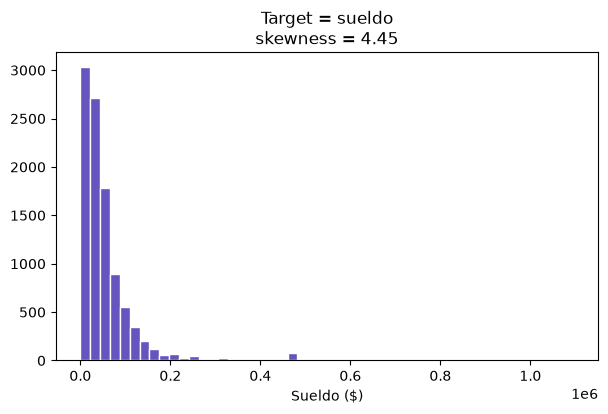

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
histograma(ax, df["income"], "Target = sueldo")
ax.set_xlabel("Sueldo ($)")
plt.show()

In [8]:
df["income"].describe()

count     10000.00
mean      54406.83
std       68071.30
min         110.00
25%       19000.00
50%       36400.00
75%       65000.00
max     1096000.00
Name: income, dtype: float64

Como se puede observar la target tiene asimetría positiva. Por esta razón, a continuación realizamos la transformación logarítmica ya que tiene valores > 0.

In [13]:
income_log = np.log(df["income"])
income = df["income"].to_numpy()
print(f"Skewness de la target original: {fmt(skew(income))}")
print(f"Skewness de la target transformada con log: {fmt(skew(income_log))}")

Skewness de la target original: 4.45
Skewness de la target transformada con log: -1.01


Como dio un valor negativo probamos con transformación Box-Cox

In [14]:
bc = PowerTransformer(method="box-cox", standardize=False) # standardize = false porque no es necesario para la target. Sí lo sería para features.

income_bc = bc.fit_transform(income.reshape(-1, 1)).ravel()

print(f"λ elegido: {fmt(bc.lambdas_[0])}") #lambdas_ es un array que devuelve el mejor lambda
print(f"Skewness de la target original: {fmt(skew(income))}")
print(f"Skewness de la target transformada con Box-Cox: {fmt(skew(income_bc))}")

λ elegido: 0.21
Skewness de la target original: 4.45
Skewness de la target transformada con Box-Cox: 0.06


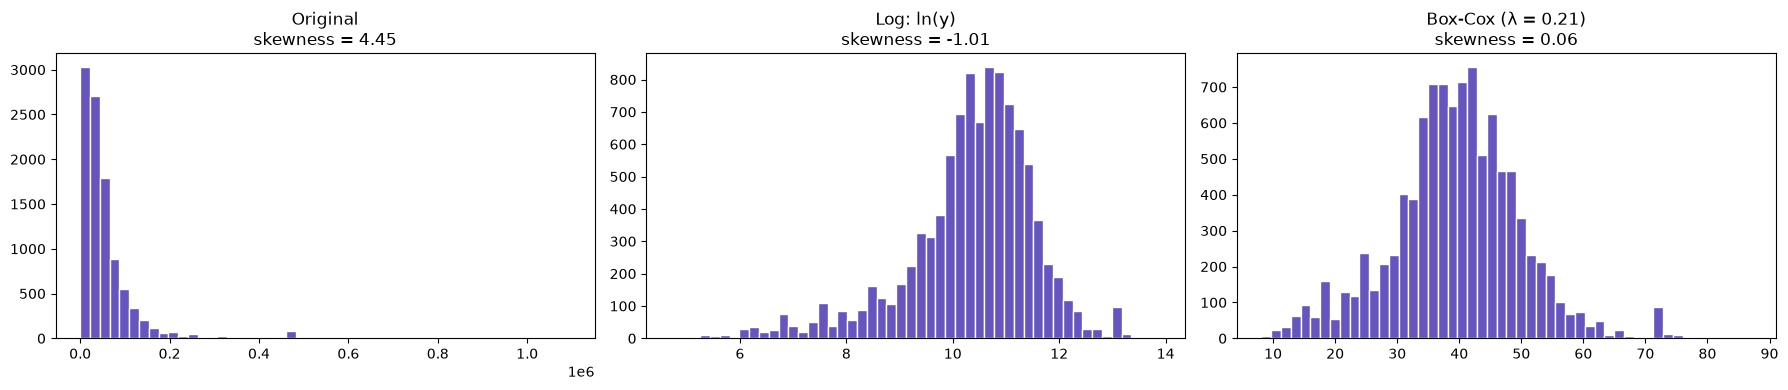

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
histograma(axes[0], income, "Original")
histograma(axes[1], income_log, "Log: ln(y)")
histograma(axes[2], income_bc, f"Box-Cox (λ = {fmt(bc.lambdas_[0])})")
plt.tight_layout()
plt.show()

### Modelo de regresión lineal

In [21]:
# 1. Separar features y target, y apartar el test final
X = df.drop(columns="income")
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Definición del preprocesamiento 
num_cols = ["age", "hours_per_week"]
cat_cols = ["education", "employer_type", "marital_status", "sex", "race", "born_in_us"]

preprocesamiento = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), cat_cols),
])

# 3. Modelo: preprocesamiento + regresión, con Box-Cox sobre la target
modelo = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", preprocesamiento),
        ("reg", LinearRegression()),
    ]),
    transformer=PowerTransformer(method="box-cox"),
)

# 4. K-fold cross validation sobre el train
kf = KFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(
    modelo, X_train, y_train, cv=kf,
    scoring=["r2", "neg_root_mean_squared_error"],
    return_train_score=True,
)

print("R² por fold:", resultados["test_r2"].round(3))
print(f"R² medio CV: {resultados['test_r2'].mean():.3f} ± {resultados['test_r2'].std():.3f}")
print(f"RMSE medio CV: {-resultados['test_neg_root_mean_squared_error'].mean():,.0f}")
print(f"R² medio train: {resultados['train_r2'].mean():.3f}")

# 5. Entrenamiento final y evaluación única en test
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(f"R² test: {r2_score(y_test, y_pred):.3f}")
print(f"RMSE test: {root_mean_squared_error(y_test, y_pred):,.0f}")


R² por fold: [0.312 0.211 0.235 0.268 0.235]
R² medio CV: 0.252 ± 0.035
RMSE medio CV: 59,316
R² medio train: 0.251
R² test: 0.228
RMSE test: 57,463


R² en train ≈ R² en validación (los dos dan ≈ 0.25): no hay sobreajuste.

El R² de test se parece al de CV: la estimación de k-fold era confiable, que es justamente lo que te garantiza no tener leakage.

R² bajo (≈ 0.25): con estas pocas variables y un modelo lineal, el sueldo se explica solo en parte. No es un problema del método.

Conclusión: todas las transformaciones (imputación, escalado, codificación y Box-Cox de la target) están dentro de un Pipeline. Así, en cada fold se ajustan solo con los datos de entrenamiento de ese fold y se aplican al fold de validación sin haberlo visto. El conjunto de test se separa antes de todo y se usa una sola vez al final

### MAE

In [22]:
pipe = Pipeline([
    ("prep", preprocesamiento),
    ("reg", LinearRegression()),
])

modelos = {
    "Target original": clone(pipe),
    "Target log": TransformedTargetRegressor(
        regressor=clone(pipe), func=np.log, inverse_func=np.exp
    ),
    "Target Box-Cox": TransformedTargetRegressor(
        regressor=clone(pipe), transformer=PowerTransformer(method="box-cox")
    ),
}

filas = []
for nombre, modelo in modelos.items():
    cv = cross_validate(modelo, X_train, y_train, cv=kf,
                        scoring=["neg_mean_absolute_error", "r2"])
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    filas.append({
        "Modelo": nombre,
        "MAE CV (media)": -cv["test_neg_mean_absolute_error"].mean(),
        "MAE CV (std)": cv["test_neg_mean_absolute_error"].std(),
        "R² CV": cv["test_r2"].mean(),
        "MAE test": mean_absolute_error(y_test, y_pred),
        "Predicciones < 0": (y_pred < 0).sum(),
    })

pd.DataFrame(filas).set_index("Modelo")


,MAE CV (media),MAE CV (std),R² CV,MAE test,Predicciones < 0
Modelo,,,,,
Target original,31452.65,1079.93,0.27,30185.66,135
Target log,29494.69,1731.31,0.19,28928.32,0
Target Box-Cox,28116.01,1514.80,0.25,27466.87,0


Box-Cox tiene el menor MAE. Reduce el error absoluto medio en unos $3.300 frente a la target original (≈ 11 % menos). La mejora se repite en CV y en test, así que no depende de una partición puntual.

La target original genera predicciones imposibles. El modelo lineal sobre la target sin transformar predice sueldos negativos en 135 casos del test (el mínimo es −$53.000). Al transformar, la inversa siempre devuelve valores positivos.

El log mejora respecto de la original, pero menos que Box-Cox. Esto confirma lo que viste con la skewness: el log corrige de más (skew −1.01). Box-Cox, con λ = 0.21, ajusta mejor y por eso también predice mejor.

¿Por qué el R² de la original es un poco más alto? El R² se basa en errores al cuadrado, así que pesa mucho los sueldos extremos (hay valores de hasta $1.096.000). El modelo sin transformar intenta acercarse a esos extremos, lo que favorece el R² pero empeora la mayoría de las predicciones. Las transformaciones comprimen la cola derecha y priorizan el error en los sueldos típicos, que es lo que mide el MAE. Es un buen punto para mencionar: la mejor métrica depende de qué errores te importan más.

Limitación. Al volver a pesos con la inversa, el modelo transformado predice algo más parecido a la mediana del sueldo que a la media condicional. Por eso tiende a subestimar los sueldos muy altos. Para el MAE eso es una ventaja: la mediana es justamente lo que minimiza el error absoluto.

Conclusión: transformar la target con Box-Cox mejora el MAE (≈ $28.100 contra ≈ $31.500 con la original) y evita predicciones negativas, a costa de un R² apenas menor, sensible a los sueldos extremos. Por eso elegimos el modelo con target Box-Cox